In [1]:
import os
import re
import sys
import json
import random
import shutil
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import csv
import yaml
from collections import Counter, defaultdict

import torch
import easyocr
from ultralytics import YOLO
from transformers import AutoModelForImageTextToText, AutoProcessor

/home/skinnydevi/Development/computer-vision/P4/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ==========================================================
# 1. RANDOMNESS AND TRAINING SEED
# ==========================================================
SEED = 42


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def get_random(seed=SEED):
    """Get a Python Random instance with a given seed. Default to global seed."""

    return random.Random(seed)


set_seed(SEED)
print(f"Training seed: {SEED}")

Training seed: 42


In [3]:
# ==========================================================
# 2. ACCELERATED DEVICE DETECTION
# ==========================================================
if torch.cuda.is_available():
    DEVICE = 0
    device_desc = f"NVIDIA GPU ({torch.cuda.get_device_name(0)})"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
    device_desc = "Apple Silicon GPU (MPS)"
else:
    DEVICE = "cpu"
    device_desc = "CPU"

print(f"OS platform: {os.name}")
print("CPU Model: Intel i7-10700")
print(f"CPU name: {os.uname().sysname} {os.uname().release} {os.uname().version}")
print(f"CPU cores: {os.cpu_count()}")
print(f"RAM: {round(os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / (1024 ** 3), 2)} GB")
print(f"Python version: {sys.version}")
print(f"PyTorch version: {torch.__version__}")
print(f"OpenCV version: {cv2.__version__}")
print(f"Ultralytics YOLO loaded")
print(f"Using device: {DEVICE} ({device_desc})")
print(f"VRAM available: {round(torch.cuda.get_device_properties(0).total_memory / (1024 ** 3), 2) if torch.cuda.is_available() else 'N/A'} GB")

OS platform: posix
CPU Model: Intel i7-10700
CPU name: Linux 7.3.3-1-cachyos #1 SMP PREEMPT_DYNAMIC Sat, 07 Nov 2026 13:54:44 +0000
CPU cores: 16
RAM: 31.25 GB
Python version: 3.11.8 (main, Feb 25 2024, 04:18:18) [Clang 17.0.6 ]
PyTorch version: 2.6.0+cu124
OpenCV version: 5.0.0
Ultralytics YOLO loaded
Using device: 0 (NVIDIA GPU (NVIDIA GeForce RTX 3060 Ti))
VRAM available: 7.67 GB


In [4]:
YOLO_TRACKER_CONFIG = {
    "tracker_type": "botsort",  # Used for tracking license plates across frames
    "fuse_score": True,  # Fuse: Use detection confidence score to improve tracking
    "gmc_method": "sparseOptFlow",  # Use sparse optical flow for motion compensation
    "with_reid": False,  # REID: Use appearance features for re-identification (slower, but more robust)
    "appearance_thresh": 0.7,  # Appearance similarity threshold for re-identification
    "match_thresh": 0.75,  # Matching threshold for associating detections to existing tracks
    "new_track_thresh": 0.25,  # Confidence threshold for creating new tracks
    "proximity_thresh": 0.5,  # Proximity threshold for associating detections to existing tracks
    "track_high_thresh": 0.25,  # Confidence threshold for keeping tracks alive
    "track_low_thresh": 0.1,  # Confidence threshold for terminating tracks
    "track_buffer": 90,  # Number of frames to keep a track alive without detections
}
YOLO_TRACKER_CONFIG_PATH = Path("yolo_tracker_file.yaml").resolve()

with open(YOLO_TRACKER_CONFIG_PATH, "w") as tracker_file:
    yaml.dump(YOLO_TRACKER_CONFIG, tracker_file, default_flow_style=False)

In [5]:
class LicensePlateOCR:
    """
    Optical Character Recognition (OCR) for license plate crops supporting
    both SmolVLM and EasyOCR backends.
    """

    DEFAULT_MODEL_NAME = "HuggingFaceTB/SmolVLM-Instruct"
    DEFAULT_IMAGE_SIZE = {"shortest_edge": 768, "longest_edge": 768}
    DEFAULT_PROMPT = (
        "Read the license plate text in this image. "
        "Reply ONLY with the alphanumeric characters of the plate, "
        "without spaces or hyphens. "
        # "Accepted regex pattern: '[0-9]{4}[A-Z]{3}', '[A-Z]{1,2}[0-9]{4}[A-Z]{1,2}'"
        "Accepted regex pattern: '[0-9]{4}[A-Z]{3}'"
    )
    DEFAULT_EASYOCR_LANGUAGES = ("es",)
    ALLOWLIST = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"
    OCR_BACKENDS = ("smolvlm", "easyocr")
    INIT_BACKENDS = ("smolvlm", "easyocr", "both")

    def __init__(
        self,
        model_name=DEFAULT_MODEL_NAME,
        device=DEVICE,
        max_new_tokens=10,
        image_size=None,
        prompt=None,
        easyocr_languages=None,
        backend="both",
        default_backend=None,
    ):
        """
        Initialize SmolVLM and/or EasyOCR for license plate OCR.

        Args:
            model_name: HuggingFace model ID for SmolVLM.
            device: Target device (e.g., DEVICE from setup cell, 'cuda', 'mps', or 'cpu').
            max_new_tokens: Maximum tokens generated by SmolVLM.
            image_size: Optional SmolVLM processor image size dict.
            prompt: Optional custom prompt for SmolVLM.
            easyocr_languages: Language list for EasyOCR (default: ['es']).
            backend: Which backend(s) to load eagerly ('smolvlm', 'easyocr', or 'both').
            default_backend: Default backend used by `recognize_plate` when `backend` is omitted.
        """
        backend = backend.lower()
        if backend not in self.INIT_BACKENDS:
            raise ValueError(
                f"Unsupported backend '{backend}'. Choose from {self.INIT_BACKENDS}."
            )

        if default_backend is None:
            self.default_backend = "easyocr" if backend == "easyocr" else "smolvlm"
        else:
            self.default_backend = default_backend.lower()
            if self.default_backend not in self.OCR_BACKENDS:
                raise ValueError(
                    f"Unsupported default_backend '{default_backend}'. Choose from {self.OCR_BACKENDS}."
                )

        self.model_name = model_name
        self.device = self._resolve_device(device)
        self.max_new_tokens = max_new_tokens
        self.image_size = (
            dict(image_size) if image_size is not None else dict(self.DEFAULT_IMAGE_SIZE)
        )
        self.prompt = prompt or self.DEFAULT_PROMPT
        self.easyocr_languages = (
            list(easyocr_languages)
            if easyocr_languages is not None
            else list(self.DEFAULT_EASYOCR_LANGUAGES)
        )

        if self.device.type == "cuda":
            self.dtype = (
                torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
            )
        else:
            self.dtype = torch.float32

        self.processor = None
        self.model = None
        self.prompt_text = None
        self.easyocr_reader = None

        if backend in ("smolvlm", "both"):
            self._ensure_smolvlm()
        if backend in ("easyocr", "both"):
            self._ensure_easyocr()

    def _ensure_smolvlm(self):
        if self.processor is not None and self.model is not None:
            return

        self.processor = AutoProcessor.from_pretrained(
            self.model_name,
            size=self.image_size,
        )

        load_kwargs = {
            "dtype": self.dtype,
            "_attn_implementation": "eager",
        }
        if self.device.type == "cuda":
            try:
                self.model = AutoModelForImageTextToText.from_pretrained(
                    self.model_name,
                    device_map=str(self.device),
                    **load_kwargs,
                )
            except (ImportError, ValueError):
                self.model = AutoModelForImageTextToText.from_pretrained(
                    self.model_name,
                    **load_kwargs,
                ).to(self.device)
        else:
            self.model = AutoModelForImageTextToText.from_pretrained(
                self.model_name,
                **load_kwargs,
            ).to(self.device)

        self.model.eval()

        messages = [
            {
                "role": "user",
                "content": [
                    {"type": "image"},
                    {"type": "text", "text": self.prompt},
                ],
            }
        ]
        self.prompt_text = self.processor.apply_chat_template(
            messages, add_generation_prompt=True
        )

    def _ensure_easyocr(self):
        if self.easyocr_reader is not None:
            return

        if self.device.type == "cpu":
            gpu_arg = False
        elif self.device.type == "cuda" and self.device.index not in (None, 0):
            gpu_arg = str(self.device)
        else:
            gpu_arg = True

        self.easyocr_reader = easyocr.Reader(
            self.easyocr_languages,
            gpu=gpu_arg,
            verbose=False,
        )

    @staticmethod
    def _resolve_device(device) -> torch.device:
        if device is None:
            if torch.cuda.is_available():
                return torch.device("cuda:0")
            if torch.backends.mps.is_available():
                return torch.device("mps")
            return torch.device("cpu")
        if isinstance(device, int):
            return torch.device(f"cuda:{device}")
        return torch.device(device)

    @staticmethod
    def _to_uint8_array(image) -> np.ndarray | None:
        if image is None:
            return None

        if isinstance(image, (str, Path)):
            with Image.open(image) as img:
                rgb = np.array(img.convert("RGB"))
            arr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
        elif isinstance(image, Image.Image):
            rgb = np.array(image.convert("RGB"))
            arr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
        elif isinstance(image, np.ndarray):
            arr = image
        else:
            raise TypeError(f"Unsupported image type for OCR: {type(image)}")

        if arr.size == 0 or arr.ndim < 2 or arr.shape[0] < 2 or arr.shape[1] < 2:
            return None

        if arr.dtype != np.uint8:
            if np.issubdtype(arr.dtype, np.floating) and arr.max() <= 1.0:
                return (np.clip(arr, 0.0, 1.0) * 255).astype(np.uint8)
            return np.clip(arr, 0, 255).astype(np.uint8)

        return arr

    @classmethod
    def _prepare_pil_image(cls, image) -> Image.Image | None:
        if isinstance(image, Image.Image):
            if image.width < 2 or image.height < 2:
                return None
            return image.convert("RGB")

        arr = cls._to_uint8_array(image)
        if arr is None:
            return None

        if arr.ndim == 2:
            rgb = cv2.cvtColor(arr, cv2.COLOR_GRAY2RGB)
        elif arr.ndim == 3 and arr.shape[2] == 1:
            rgb = cv2.cvtColor(arr[:, :, 0], cv2.COLOR_GRAY2RGB)
        elif arr.ndim == 3 and arr.shape[2] == 3:
            rgb = cv2.cvtColor(arr, cv2.COLOR_BGR2RGB)
        elif arr.ndim == 3 and arr.shape[2] == 4:
            rgb = cv2.cvtColor(arr, cv2.COLOR_BGRA2RGB)
        else:
            raise ValueError(f"Unsupported ndarray image shape: {arr.shape}")

        return Image.fromarray(rgb)

    @classmethod
    def _prepare_easyocr_image(
        cls, image, preprocess: bool = True
    ) -> np.ndarray | None:
        arr = cls._to_uint8_array(image)
        if arr is None:
            return None

        if arr.ndim == 2:
            gray = arr
        elif arr.ndim == 3 and arr.shape[2] == 1:
            gray = arr[:, :, 0]
        elif arr.ndim == 3 and arr.shape[2] == 3:
            gray = cv2.cvtColor(arr, cv2.COLOR_BGR2GRAY) if preprocess else arr
        elif arr.ndim == 3 and arr.shape[2] == 4:
            gray = (
                cv2.cvtColor(arr, cv2.COLOR_BGRA2GRAY)
                if preprocess
                else cv2.cvtColor(arr, cv2.COLOR_BGRA2BGR)
            )
        else:
            raise ValueError(f"Unsupported ndarray image shape: {arr.shape}")

        if not preprocess:
            return gray

        h, w = gray.shape[:2]
        if h < 100 or w < 300:
            gray = cv2.resize(gray, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC)
        return cv2.GaussianBlur(gray, (5, 5), 0)

    @staticmethod
    def clean_plate_text(text: str) -> str:
        """
        Normalize OCR output to uppercase alphanumeric characters.
        """
        return re.sub(r"[^A-Z0-9]", "", str(text).upper())

    def recognize_plate_smolvlm(self, image, clean: bool = True) -> str:
        """
        Extract license plate text using SmolVLM from a cropped BGR/grayscale array,
        PIL Image, or file path.
        """
        self._ensure_smolvlm()

        pil_image = self._prepare_pil_image(image)
        if pil_image is None:
            return ""

        inputs = self.processor(
            text=self.prompt_text,
            images=[pil_image],
            return_tensors="pt",
        ).to(self.device)

        with torch.inference_mode():
            generated_ids = self.model.generate(
                **inputs,
                max_new_tokens=self.max_new_tokens,
                do_sample=False,
            )

        prompt_length = inputs["input_ids"].shape[1]
        plate_text = self.processor.batch_decode(
            generated_ids[:, prompt_length:],
            skip_special_tokens=True,
        )[0].strip()

        return self.clean_plate_text(plate_text) if clean else plate_text

    def recognize_plate_easyocr(
        self, image, clean: bool = True, preprocess: bool = True
    ) -> str:
        """
        Extract license plate text using EasyOCR from a cropped BGR/grayscale array,
        PIL Image, or file path.
        """
        self._ensure_easyocr()

        ocr_image = self._prepare_easyocr_image(image, preprocess=preprocess)
        if ocr_image is None:
            return ""

        texts = self.easyocr_reader.readtext(
            ocr_image,
            detail=0,
            allowlist=self.ALLOWLIST,
            min_size=10,
        )
        if not texts:
            return ""

        if not clean:
            return " ".join(str(t).strip() for t in texts if str(t).strip()).strip()

        cleaned_parts = [self.clean_plate_text(t) for t in texts]
        cleaned_parts = [part for part in cleaned_parts if part]
        if not cleaned_parts:
            return ""

        for part in cleaned_parts:
            if len(part) == 7:
                return part

        return "".join(cleaned_parts)

    def recognize_plate(
        self, image, backend: str | None = None, clean: bool = True
    ) -> str:
        """
        Extract license plate text using the specified or default OCR backend
        ('smolvlm' or 'easyocr').
        """
        selected_backend = (backend or self.default_backend).lower()
        if selected_backend == "smolvlm":
            return self.recognize_plate_smolvlm(image, clean=clean)
        if selected_backend == "easyocr":
            return self.recognize_plate_easyocr(image, clean=clean)
        raise ValueError(
            f"Unsupported OCR backend '{selected_backend}'. Choose from {self.OCR_BACKENDS}."
        )
    
    def _rotate_plate_expanded(
        self,
        image: np.ndarray,
        angle: float,
        interpolation: int = cv2.INTER_CUBIC,
        border_mode: int = cv2.BORDER_REPLICATE,
    ) -> np.ndarray:
        """
        Rotate an image around its center while expanding the canvas so no content is clipped.
        """
        
        h, w = image.shape[:2]
        rad = np.deg2rad(abs(angle))
        cos_a = float(np.cos(rad))
        sin_a = float(np.sin(rad))
        new_w = max(w, int(np.ceil(w * cos_a + h * sin_a)))
        new_h = max(h, int(np.ceil(h * cos_a + w * sin_a)))
    
        rot_mat = cv2.getRotationMatrix2D((w / 2.0, h / 2.0), angle, 1.0)
        rot_mat[0, 2] += (new_w - w) / 2.0
        rot_mat[1, 2] += (new_h - h) / 2.0
    
        return cv2.warpAffine(
            image,
            rot_mat,
            (new_w, new_h),
            flags=interpolation,
            borderMode=border_mode,
        )
    
    def _estimate_plate_skew_angle(
        self, image: np.ndarray, max_angle: float = 25.0
    ) -> float:
        """
        Estimate the counter-clockwise deskew angle (degrees) that aligns plate characters
        horizontally using mask-normalized projection-profile variance.
        """
        
        # Preprocess the image to enhance edges and suppress background
        h, w = image.shape[:2]
        scale = min(1.0, 220.0 / max(w, 1)) if w > 220 else max(1.0, 64.0 / max(h, 1))
        work_w = max(32, int(round(w * scale)))
        work_h = max(24, int(round(h * scale)))
        work = cv2.resize(
            image,
            (work_w, work_h),
            interpolation=cv2.INTER_AREA if scale < 1.0 else cv2.INTER_CUBIC,
        )
    
        # Compute edge and background-suppressed features:
        # 1. Sobel gradient magnitude (gx)
        gray = cv2.cvtColor(work, cv2.COLOR_BGR2GRAY).astype(np.float32)
        gx = np.abs(cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3))
        bg = cv2.GaussianBlur(gray, (0, 0), sigmaX=max(4.0, work_h * 0.22))
        # 2. Difference-of-Gaussians (DoG) for background suppression
        dog = np.maximum(bg - gray, 0.0)
    
        gx_scale = max(float(np.percentile(gx, 99)), 1e-6)
        dog_scale = max(float(np.percentile(dog, 99)), 1e-6)
    
        # 3. Combine gx and DoG into a foreground mask (fg) normalized by a valid border mask
        border = 2
        valid = np.ones((work_h, work_w), dtype=np.float32)
        valid[:border, :] = 0.0
        valid[-border:, :] = 0.0
        valid[:, :border] = 0.0
        valid[:, -border:] = 0.0
    
        # 4. Compute a combined foreground mask and suppress low values based on the 55th percentile
        fg = (0.55 * (gx / gx_scale) + 0.45 * (dog / dog_scale)) * valid
        interior = fg[valid > 0]
        if interior.size == 0 or float(np.max(interior)) <= 0.0:
            return 0.0
        fg = np.maximum(fg - float(np.percentile(interior, 55)), 0.0)
    
        # 5. Stack the foreground and valid masks for rotation and scoring
        stacked = np.ascontiguousarray(np.dstack([fg, valid]), dtype=np.float32)
    
        def _score_angle(angle: float) -> float:
            warped = self._rotate_plate_expanded(
                stacked,
                angle,
                interpolation=cv2.INTER_LINEAR,
                border_mode=cv2.BORDER_CONSTANT,
            )
            row_fg = warped[:, :, 0].sum(axis=1)
            row_mk = warped[:, :, 1].sum(axis=1)
            keep = row_mk >= max(10.0, 0.60 * work_w)
            if np.count_nonzero(keep) < 6:
                return 0.0
            
            return float(np.var(row_fg[keep] / row_mk[keep]))
    
        zero_score = _score_angle(0.0)
        if zero_score <= 1e-9:
            return 0.0
    
        # Coarse-to-fine search for the best deskew angle
        best_angle = 0.0
        best_score = zero_score
        for angle in np.arange(-max_angle, max_angle + 0.1, 1.0):
            score = _score_angle(float(angle))
            if score > best_score:
                best_score = score
                best_angle = float(angle)
    
        # Fine search around the best coarse angle
        coarse_center = best_angle
        fine_low = max(-max_angle, coarse_center - 1.5)
        fine_high = min(max_angle, coarse_center + 1.5)
        for angle in np.arange(fine_low, fine_high + 0.01, 0.25):
            score = _score_angle(float(angle))
            if score > best_score:
                best_score = score
                best_angle = float(angle)
    
        if abs(best_angle) < 1.0 or best_score < zero_score * 1.15:
            return 0.0
        
        return best_angle
    
    def clean_and_augment_plate_image(self, plate_crop: cv2.Mat) -> cv2.Mat:
        """
        Restore and normalize a raw plate crop (tightly zoomed-in, pixelated,
        blurry, and/or skewed) into a higher-resolution, deskewed, sharp BGR plate
        image with quiet margins for OCR.
        """
        
        if (
            plate_crop is None
            or plate_crop.size == 0
            or plate_crop.shape[0] < 6
            or plate_crop.shape[1] < 6
        ):
            print("Warning: Plate crop is too small or empty for OCR.")
            return plate_crop
    
        image = plate_crop
        if image.dtype != np.uint8:
            if np.issubdtype(image.dtype, np.floating) and float(image.max()) <= 1.0:
                image = (np.clip(image, 0.0, 1.0) * 255).astype(np.uint8)
            else:
                image = np.clip(image, 0, 255).astype(np.uint8)
    
        if image.ndim == 2:
            image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
        elif image.ndim == 3 and image.shape[2] == 1:
            image = cv2.cvtColor(image[:, :, 0], cv2.COLOR_GRAY2BGR)
        elif image.ndim == 3 and image.shape[2] == 4:
            image = cv2.cvtColor(image, cv2.COLOR_BGRA2BGR)
    
        # 1. Upscale low-resolution / pixelated crops while preserving aspect ratio.
        h, w = image.shape[:2]
        if h < 128 or w < 300:
            scale = min(max(128.0 / h, 300.0 / w), 16.0, 768.0 / max(h, w))
            scale = max(scale, 1.0)
            image = cv2.resize(
                image,
                (int(round(w * scale)), int(round(h * scale))),
                interpolation=cv2.INTER_CUBIC,
            )
    
        # 2. Reduce pixelation / compression block noise while keeping character edges.
        image = cv2.bilateralFilter(image, d=5, sigmaColor=30, sigmaSpace=30)
    
        # 3. Reverse rotate plates on an expanded canvas without clipping corners.
        deskew_angle = self._estimate_plate_skew_angle(image)
        if deskew_angle != 0.0:
            image = self._rotate_plate_expanded(
                image,
                deskew_angle,
                interpolation=cv2.INTER_CUBIC,
                border_mode=cv2.BORDER_REPLICATE,
            )
    
        # 4. Enhance local contrast (CLAHE on LAB L) and apply blur-adaptive sharpening.
        lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
        l_chan, a_chan, b_chan = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=1.8, tileGridSize=(8, 4)) # CLAHE: Contrast Limited Adaptive Histogram Equalization
        l_eq = clahe.apply(l_chan)
    
        lap_var = float(cv2.Laplacian(l_eq, cv2.CV_64F).var())
        sharpen_amount = float(np.clip(1.15 - (lap_var / 500.0) * 0.6, 0.55, 1.15))
        l_blur = cv2.GaussianBlur(l_eq, (0, 0), sigmaX=2.0)
        l_sharp = cv2.addWeighted(
            l_eq,
            1.0 + sharpen_amount,
            l_blur,
            -sharpen_amount,
            0,
        )
        enhanced = cv2.cvtColor(
            cv2.merge((l_sharp, a_chan, b_chan)), cv2.COLOR_LAB2BGR
        )
    
        # 5. Add quiet border margins around tightly zoomed-in detections.
        out_h, out_w = enhanced.shape[:2]
        pad_y = max(12, int(round(0.14 * out_h)))
        pad_x = max(20, int(round(0.08 * out_w)))
        return cv2.copyMakeBorder(
            enhanced,
            pad_y,
            pad_y,
            pad_x,
            pad_x,
            cv2.BORDER_CONSTANT,
            value=(240, 240, 240),
        )

In [6]:
class PedestrianOcclusionManager:
    """
    Manages the continuity of pedestrian identities when they suffer occlusions
    (e.g., when a vehicle passes in front of a person).
    """

    def __init__(self, max_gap_frames=90, max_distance=220, min_similarity=0.60):
        self.max_gap_frames = max_gap_frames
        self.max_distance = max_distance
        self.min_similarity = min_similarity

        self.id_remap = {}  # raw_yolo_id -> canonical_id
        self.lost_tracks = {}  # canonical_id -> dict with info of last known state
        self.active_tracks = (
            {}
        )  # canonical_id -> dict with last box and color histogram

    def resolve_id(self, raw_id):
        curr = raw_id
        visited = set()
        while curr in self.id_remap and curr not in visited:
            visited.add(curr)
            curr = self.id_remap[curr]

        return curr

    @staticmethod
    def extract_color_hist(frame, box):
        x1, y1, x2, y2 = box
        crop = frame[max(0, y1) : max(0, y2), max(0, x1) : max(0, x2)]
        if crop.size == 0 or crop.shape[0] < 6 or crop.shape[1] < 6:
            return None

        hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
        hist = cv2.calcHist([hsv], [0, 1], None, [16, 16], [0, 180, 0, 256])
        cv2.normalize(hist, hist, 0, 1, cv2.NORM_MINMAX)
        return hist

    @staticmethod
    def get_center(box):
        return ((box[0] + box[2]) / 2.0, (box[1] + box[3]) / 2.0)

    @staticmethod
    def compute_distance(p1, p2):
        """Euclidean distance between two points p1 and p2, where each point is (x, y)"""
        return ((p1[0] - p2[0]) ** 2 + (p1[1] - p2[1]) ** 2) ** 0.5

    def _is_track_known(self, raw_id, canonical_id):
        return raw_id in self.id_remap or canonical_id in self.active_tracks

    def _check_lost_tracks(self, current_frame, p_center, p_hist):
        # If it's a new track we don't know created by YOLO
        best_match_id = None
        best_score = -1.0

        for lost_id, lost_info in list(self.lost_tracks.items()):
            # Check if the lost track is too old
            gap = current_frame - lost_info["last_frame"]
            if gap > self.max_gap_frames:
                continue

            # Check distance between last known position and current detection
            lost_center = self.get_center(lost_info["last_box"])
            dist = self.compute_distance(p_center, lost_center)
            max_allowed_dist = min(self.max_distance, 40.0 + gap * 3.5)
            if dist > max_allowed_dist:
                continue

            # HSV color histogram similarity (0.0 to 1.0, higher is more similar)
            similarity = 0.5
            if p_hist is not None and lost_info["color_hist"] is not None:
                similarity = cv2.compareHist(
                    p_hist, lost_info["color_hist"], cv2.HISTCMP_CORREL
                )

            # If the lost track was occluded by a vehicle and reappears nearby,
            # or if the similarity is high
            score = similarity - (dist / 1200.0)
            if (similarity >= self.min_similarity) or (
                lost_info["occluded_by_vehicle"] and dist < 90 and similarity > 0.35
            ):
                if score > best_score:
                    best_score = score
                    best_match_id = lost_id

        return best_match_id, best_score

    def _relink_track(self, raw_id, best_match_id):
        self.id_remap[raw_id] = best_match_id
        if best_match_id in self.lost_tracks:
            del self.lost_tracks[best_match_id]

    def _update_active_track(self, canonical_id, p_box, p_hist, current_frame):
        self.active_tracks[canonical_id] = {
            "last_frame": current_frame,
            "last_box": p_box,
            "color_hist": (
                p_hist
                if p_hist is not None
                else self.active_tracks.get(canonical_id, {}).get("color_hist")
            ),
        }

    def _process_yolo_tracks(self, people, frame, current_frame):
        current_canonical_ids = set()

        for person in people:
            raw_id = person["track_id"]
            if raw_id == "" or raw_id is None:
                continue

            canonical_id = self.resolve_id(raw_id)
            p_box = person["box"]
            p_center = self.get_center(p_box)
            p_hist = self.extract_color_hist(frame, p_box)

            if self._is_track_known(raw_id, canonical_id):
                continue  # Already known track, no need to check lost tracks

            # Check lost tracks for potential matches
            best_match_id, _ = self._check_lost_tracks(current_frame, p_center, p_hist)

            if best_match_id is not None:
                # Re-link track: assign original ID
                canonical_id = best_match_id
                self._relink_track(raw_id, best_match_id)

            person["track_id"] = canonical_id
            current_canonical_ids.add(canonical_id)

            # Update active tracks with the latest information
            self._update_active_track(canonical_id, p_box, p_hist, current_frame)

        return current_canonical_ids

    def _process_missing_people_in_frame(self, current_canonical_ids, vehicle_boxes):
        disappeared_ids = set(self.active_tracks.keys()) - current_canonical_ids
        for dis_id in disappeared_ids:
            dis_info = self.active_tracks[dis_id]
            dis_box = dis_info["last_box"]
            dis_center = self.get_center(dis_box)

            # Comprobar si desapareció solapado con un vehículo
            was_occluded = False
            for vx1, vy1, vx2, vy2 in vehicle_boxes:
                if (vx1 <= dis_center[0] <= vx2 and vy1 <= dis_center[1] <= vy2) or (
                    max(dis_box[0], vx1) < min(dis_box[2], vx2)
                    and max(dis_box[1], vy1) < min(dis_box[3], vy2)
                ):
                    was_occluded = True
                    break

            self.lost_tracks[dis_id] = {
                "last_frame": dis_info["last_frame"],
                "last_box": dis_box,
                "color_hist": dis_info["color_hist"],
                "occluded_by_vehicle": was_occluded,
            }
            del self.active_tracks[dis_id]

    def _cleanup_old_lost_tracks(self, current_frame):
        for lost_id in list(self.lost_tracks.keys()):
            if (
                current_frame - self.lost_tracks[lost_id]["last_frame"]
                > self.max_gap_frames
            ):
                del self.lost_tracks[lost_id]

    def process_people_in_frame(self, frame, people, current_frame, vehicle_boxes):
        """
        Process the people in the current frame, resolving ID switches due to occlusion.
        """

        # Process YOLO trackers and update active tracks
        current_canonical_ids = self._process_yolo_tracks(people, frame, current_frame)

        # Identify which pedestrians disappeared in this frame
        self._process_missing_people_in_frame(current_canonical_ids, vehicle_boxes)

        # Clean up lost tracks that have exceeded the maximum gap frames
        self._cleanup_old_lost_tracks(current_frame)

In [7]:
class LicensePlateVideoProcessor:
    """
    Processes a video to detect and track vehicles, license plates and pedestrians.
    Applies occlusion management, hierarchical license plate memory and track class consensus.
    Saves the annotated video and generates the results CSV.
    """

    def __init__(
        self,
        vehicle_model,
        plate_model,
        tracker_config=YOLO_TRACKER_CONFIG_PATH,
        max_gap_frames=90,
        max_distance=220,
        apply_censoring=False,
    ):
        self.vehicle_model: YOLO = vehicle_model
        self.plate_model: YOLO = plate_model
        self.tracker_config = tracker_config
        self.occlusion_manager = PedestrianOcclusionManager(
            max_gap_frames=max_gap_frames, max_distance=max_distance
        )
        self.plate_ocr = LicensePlateOCR(easyocr_languages=["es", "en"], backend="both")
        self.apply_censoring = apply_censoring

        self.video_width = None
        self.video_height = None
        self.video_fps = None
        self.video_total_frames = None

        self.vehicle_classes = {
            0: "person",
            2: "car",
            3: "motorbike",
            5: "bus",
            # 7: "truck",
        }

        self.csv_columns = [
            "fotograma",
            "tipo_objeto",
            "confianza",
            "identificador_tracking",
            "x1",
            "y1",
            "x2",
            "y2",
            "matrícula_en_su_caso",
            "confianza",
            "mx1",
            "my1",
            "mx2",
            "my2",
            "texto_matricula",
        ]

        # Store the history of license plate readings for each vehicle ID
        self.vehicle_plate_registry = defaultdict(
            lambda: {
                "seen_count": 0,
                "text_readings": [],
                "last_box": None,
                "last_conf": 0.0,
                "last_seen_frame": -1,
            }
        )
        self.PLATE_TEXT_BLACKLIST = set([
            "", "None", "NONE", "0000", "5555", 
            "094A", "0000AAA", "00000000", "15221522", 
            "1234567", "12345678", "1234", "1234AB", 
            "123456"
        ])

        # Store the history of detected classes for each track ID
        self.track_class_history = defaultdict(lambda: Counter())
        self.confirmed_plates = set()
        self.raw_detection_counts = {name: 0 for name in self.vehicle_classes.values()}
        self.raw_detection_counts["license_plate"] = 0

    def box_values(self, box):
        """
        Get the bounding box coordinates, confidence and track ID from a YOLO box object.
        """

        x1, y1, x2, y2 = [int(v) for v in box.xyxy[0].tolist()]
        confidence = float(box.conf[0])
        track_id = int(box.id[0]) if box.id is not None else ""

        return x1, y1, x2, y2, confidence, track_id

    def plate_belongs_to_vehicle(self, plate_box, vehicle_box):
        """
        Determine if a detected license plate belongs to a detected vehicle based on bounding box overlap and position.
        """

        px1, py1, px2, py2 = plate_box
        vx1, vy1, vx2, vy2 = vehicle_box

        # Test if center of plate is inside vehicle box
        pcx = (px1 + px2) / 2.0
        pcy = (py1 + py2) / 2.0
        if vx1 <= pcx <= vx2 and vy1 <= pcy <= vy2:
            return True

        # Check if the intersection of the two boxes is at least 50% of the plate area
        ix1 = max(px1, vx1)
        iy1 = max(py1, vy1)
        ix2 = min(px2, vx2)
        iy2 = min(py2, vy2)
        if ix1 < ix2 and iy1 < iy2:
            inter_area = (ix2 - ix1) * (iy2 - iy1)
            plate_area = max(1, (px2 - px1) * (py2 - py1))
            if (inter_area / plate_area) >= 0.5:
                return True

        return False

    def _prepare_video_writer(
        self, input_video_path, output_video_path, max_frames=None
    ):
        video_capture = cv2.VideoCapture(str(input_video_path))
        if not video_capture.isOpened():
            raise RuntimeError(f"Could not open video: {input_video_path}")

        self.video_width = int(video_capture.get(cv2.CAP_PROP_FRAME_WIDTH))
        self.video_height = int(video_capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
        self.video_fps = video_capture.get(cv2.CAP_PROP_FPS) or 25.0
        self.video_total_frames = int(video_capture.get(cv2.CAP_PROP_FRAME_COUNT))

        if max_frames is not None:
            self.video_total_frames = min(self.video_total_frames, max_frames)

        writer = cv2.VideoWriter(
            str(output_video_path),
            cv2.VideoWriter_fourcc(*"mp4v"),
            self.video_fps,
            (self.video_width, self.video_height),
        )

        return video_capture, writer

    def _detect_vehicles(self, frame, conf_threshold):
        return self.vehicle_model.track(
            frame,
            classes=list(self.vehicle_classes.keys()),
            conf=conf_threshold,
            persist=True,
            tracker=self.tracker_config,
            verbose=False,
        )

    def _detect_license_plates(self, frame, conf_threshold):
        return self.plate_model(
            frame,
            conf=conf_threshold,
            verbose=False,
        )

    def _classify_detections(self, vehicle_results):
        current_vehicles = []
        current_people = []
        vehicle_boxes = []
        if not vehicle_results or len(vehicle_results[0].boxes) == 0:
            return current_vehicles, current_people, vehicle_boxes

        for box in vehicle_results[0].boxes:
            x1, y1, x2, y2, conf, track_id = self.box_values(box)
            cls_id = int(box.cls[0])

            # Map the YOLO class ID to a human-readable type
            raw_type = self.vehicle_classes.get(cls_id)
            if raw_type is None:
                continue

            # Update raw class count
            self.raw_detection_counts[raw_type] += 1
            item = {
                "type": raw_type,
                "confidence": conf,
                "track_id": track_id,
                "box": (x1, y1, x2, y2),
            }

            if raw_type == "person":
                current_people.append(item)
            else:
                current_vehicles.append(item)
                vehicle_boxes.append((x1, y1, x2, y2))

        return current_vehicles, current_people, vehicle_boxes

    def _update_track_class_history(self, tracks: list):
        for track in tracks:
            tid = track["track_id"]
            if tid == "":
                continue

            self.track_class_history[tid][track["type"]] += 1
            # Use mode (moda) to determine the dominant class for this track
            dominant_type = self.track_class_history[tid].most_common(1)[0][0]
            track["type"] = dominant_type
            
    def _read_plate_text(self, frame: cv2.Mat, plate_box: tuple[float, float, float, float]) -> str:
        px1, py1, px2, py2 = plate_box
        plate_crop = frame[max(0, py1) : max(0, py2), max(0, px1) : max(0, px2)]
        plate_crop_threshold = 12
        if plate_crop.size == 0 or plate_crop.shape[0] < plate_crop_threshold or plate_crop.shape[1] < plate_crop_threshold:
            print(f"Warning: Plate crop is too small or empty for OCR: {plate_box}")
            return "None"
        
        plate_crop = self.plate_ocr.clean_and_augment_plate_image(plate_crop.copy())
        plate_text = self.plate_ocr.recognize_plate(plate_crop, backend="smolvlm", clean=True)
        if plate_text in self.PLATE_TEXT_BLACKLIST or len(plate_text) > 10 or len(plate_text) < 3:
            plate_text = "None"
            
        return plate_text
    
    def _is_valid_plate_text(self, plate_text: str) -> bool:
        return (
            bool(plate_text)
            and plate_text != "None"
            and plate_text not in self.PLATE_TEXT_BLACKLIST
            and len(plate_text) <= 10
        )
    
    def _get_most_common_plate_text(self, vehicle_id: int | str) -> str:
        if vehicle_id == "" or vehicle_id not in self.vehicle_plate_registry:
            return "None"
        
        plate_registry = self.vehicle_plate_registry[vehicle_id]
        valid_readings = [
            text
            for text in plate_registry["text_readings"]
            if self._is_valid_plate_text(text)
        ]
        if not valid_readings:
            return "None"
        
        text_counter = Counter(valid_readings)
        most_common_text, _ = text_counter.most_common(1)[0]
        return most_common_text
    
    def _get_plate_text_none_count(self, vehicle_id: int) -> int:
        plate_registry = self.vehicle_plate_registry[vehicle_id]
        if not plate_registry["text_readings"]:
            return 0
        
        return sum(
            1 for text in plate_registry["text_readings"] if not self._is_valid_plate_text(text)
        )

    def _process_license_plates(self, plate_results, current_vehicles, frame: cv2.Mat, frame_number: int):
        current_plates = []
        if plate_results is None or len(plate_results) == 0:
            return current_plates

        # Process each detected license plate and associate it with a vehicle if possible
        for box in plate_results[0].boxes:
            px1, py1, px2, py2 = [int(v) for v in box.xyxy[0].tolist()]
            plate_conf = float(box.conf[0])

            current_plates.append(
                {
                    "box": (px1, py1, px2, py2),
                    "confidence": plate_conf,
                    "associated": False,
                    "plate_text": self._read_plate_text(frame.copy(), (px1, py1, px2, py2))
                }
            )

            self.raw_detection_counts["license_plate"] += 1

        for plate in current_plates:
            matched_vehicle = None
            for vehicle in current_vehicles:
                if self.plate_belongs_to_vehicle(plate["box"], vehicle["box"]):
                    matched_vehicle = vehicle
                    break

            if matched_vehicle is not None:
                plate["associated"] = True
                plate["vehicle_id"] = matched_vehicle["track_id"]
                if matched_vehicle["track_id"] != "":
                    self.confirmed_plates.add(matched_vehicle["track_id"])
                    plate_track_registry = self.vehicle_plate_registry[matched_vehicle["track_id"]]
                    plate_track_registry["last_box"] = plate["box"]
                    plate_track_registry["last_conf"] = plate["confidence"]
                    plate_track_registry["seen_count"] += 1
                    plate_track_registry["text_readings"].append(plate["plate_text"])
                    plate_track_registry["last_seen_frame"] = frame_number
            else:
                plate["vehicle_id"] = ""

        return current_plates
        

    def _write_vehicles_in_csv(
        self,
        csv_writer,
        annotated_frame,
        frame_number,
        current_vehicles,
        current_plates,
    ):
        for vehicle in current_vehicles:
            # Get bbox
            vx1, vy1, vx2, vy2 = vehicle["box"]
            v_id = vehicle["track_id"]

            # Did we find a license plate in this frame for this vehicle?
            plate_in_this_frame = next(
                (
                    plate
                    for plate in current_plates
                    if plate["associated"]
                    and self.plate_belongs_to_vehicle(plate["box"], vehicle["box"])
                ),
                None,
            )

            if plate_in_this_frame is not None:
                px1, py1, px2, py2 = plate_in_this_frame["box"]
                csv_writer.writerow(
                    [
                        frame_number,
                        vehicle["type"],
                        f"{vehicle['confidence']:.4f}",
                        v_id,
                        vx1,
                        vy1,
                        vx2,
                        vy2,
                        "yes",
                        f"{plate_in_this_frame['confidence']:.4f}",
                        px1,
                        py1,
                        px2,
                        py2,
                        plate_in_this_frame["plate_text"],
                    ]
                )
            else:
                csv_writer.writerow(
                    [
                        frame_number,
                        vehicle["type"],
                        f"{vehicle['confidence']:.4f}",
                        v_id,
                        vx1,
                        vy1,
                        vx2,
                        vy2,
                        "no",
                        "",
                        "",
                        "",
                        "",
                        "",
                        "",
                    ]
                )

            # Draw vehicle bounding box in CYAN
            cv2.rectangle(annotated_frame, (vx1, vy1), (vx2, vy2), (255, 120, 0), 2)
            v_label = f"{vehicle['type']} ID:{v_id} {vehicle['confidence']:.2f}"
            cv2.putText(
                annotated_frame,
                v_label,
                (vx1, max(vy1 - 8, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 140, 0),
                2,
            )

    def _write_people_to_csv(
        self, csv_writer, annotated_frame, frame_number, current_people
    ):
        for person in current_people:
            px1, py1, px2, py2 = person["box"]
            p_id = person["track_id"]

            csv_writer.writerow(
                [
                    frame_number,
                    person["type"],
                    f"{person['confidence']:.4f}",
                    p_id,
                    px1,
                    py1,
                    px2,
                    py2,
                    "no",
                    "",
                    "",
                    "",
                    "",
                    "",
                    "",
                ]
            )

            # Draw person bounding box in ORANGE
            cv2.rectangle(annotated_frame, (px1, py1), (px2, py2), (0, 165, 255), 2)
            p_label = f"{person['type']} ID:{p_id} {person['confidence']:.2f}"
            cv2.putText(
                annotated_frame,
                p_label,
                (px1, max(py1 - 8, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 165, 255),
                2,
            )

    def _write_plates_to_csv(
        self, csv_writer, annotated_frame, frame_number, current_plates
    ):
        for plate in current_plates:
            px1, py1, px2, py2 = plate["box"]

            # Write orphan license plates
            if not plate["associated"]:
                csv_writer.writerow(
                    [
                        frame_number,
                        "license_plate",
                        f"{plate['confidence']:.4f}",
                        "",
                        px1,
                        py1,
                        px2,
                        py2,
                        "yes",
                        f"{plate['confidence']:.4f}",
                        px1,
                        py1,
                        px2,
                        py2,
                        plate["plate_text"],
                    ]
                )

            # Draw license plate bounding box in RED
            cv2.rectangle(annotated_frame, (px1, py1), (px2, py2), (0, 0, 255), 2)
            vehicle_id = plate.get("vehicle_id", "")
            most_common_plate_text = (
                self._get_most_common_plate_text(vehicle_id)
                if vehicle_id != ""
                else plate["plate_text"]
            )
            plate_label = f"MATRICULA [{most_common_plate_text}] {plate['confidence']:.2f}".strip()
            cv2.putText(
                annotated_frame,
                plate_label,
                (px1, max(py1 - 8, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (0, 0, 255),
                2,
            )

    def _write_frame_and_csv(
        self,
        frame,
        frame_number,
        csv_writer,
        current_vehicles,
        current_people,
        current_plates,
    ):
        annotated_frame = frame.copy()

        self._write_vehicles_in_csv(
            csv_writer, annotated_frame, frame_number, current_vehicles, current_plates
        )
        self._write_people_to_csv(
            csv_writer, annotated_frame, frame_number, current_people
        )
        
        # Apply optional face censoring
        self._apply_incoming_car_censor(annotated_frame, current_vehicles)
        self._apply_people_censor(annotated_frame, current_people)
        
        self._write_plates_to_csv(
            csv_writer, annotated_frame, frame_number, current_plates
        )

        return annotated_frame

    def _create_hud_overlay(
        self, annotated_frame, frame_number, min_frames_to_confirm: int
    ):
        hud_overlay = annotated_frame.copy()
        cv2.rectangle(hud_overlay, (0, 0), (self.video_width, 40), (25, 25, 25), -1)
        cv2.addWeighted(hud_overlay, 0.65, annotated_frame, 0.35, 0, annotated_frame)

        # Get classes for HUD
        hud_confirmed = defaultdict(int)
        for tid, hist in self.track_class_history.items():
            if sum(hist.values()) >= min_frames_to_confirm:
                dom_cls = hist.most_common(1)[0][0]
                hud_confirmed[dom_cls] += 1

        hud_text = (
            f"Fotograma: {frame_number}/{self.video_total_frames} | "
            f"Personas: {hud_confirmed['person']} | "
            f"Coches: {hud_confirmed['car']} | "
            f"Motos: {hud_confirmed['motorbike']} | "
            f"Autobuses: {hud_confirmed['bus']} | "
            # f"Camiones: {hud_confirmed['truck']} | "
            f"Matriculas: {len(self.confirmed_plates)}"
        )
        cv2.putText(
            annotated_frame,
            hud_text,
            (12, 26),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            (255, 255, 255),
            2,
        )

    def _apply_people_censor(self, annotated_frame, current_people):
        if not self.apply_censoring:
            return

        for person in current_people:
            px1, py1, px2, py2 = person["box"]

            # Apply blur to a person's bbox upper half
            censor_area = (px1, py1, px2, py1 + (py2 - py1) // 4)
            censor_crop = annotated_frame[
                censor_area[1] : censor_area[3], censor_area[0] : censor_area[2]
            ]
            if censor_crop.size > 0:
                blurred_crop = cv2.GaussianBlur(censor_crop, (25, 25), 30)
                annotated_frame[
                    censor_area[1] : censor_area[3], censor_area[0] : censor_area[2]
                ] = blurred_crop

    def _apply_incoming_car_censor(self, annotated_frame, current_vehicles):
        if not self.apply_censoring:
            return

        for vehicle in current_vehicles:
            if vehicle["confidence"] < 0.65:
                continue

            vx1, vy1, vx2, vy2 = vehicle["box"]
            # Apply blur to the car's bounding box
            censor_area = (vx1, vy1, vx2, vy1 + (vy2 - vy1) // 3)
            censor_crop = annotated_frame[
                censor_area[1] : censor_area[3], censor_area[0] : censor_area[2]
            ]
            if censor_crop.size > 0:
                blurred_crop = cv2.GaussianBlur(censor_crop, (25, 25), 30)
                annotated_frame[
                    censor_area[1] : censor_area[3], censor_area[0] : censor_area[2]
                ] = blurred_crop

    def _process_video_frame(
        self, frame, csv_writer, frame_number: int, conf_threshold: float
    ):
        # 1 - Process vehicle detection and tracking
        vehicle_results = self._detect_vehicles(frame, conf_threshold)

        # 2 - Process license plate detection and tracking
        plate_results = self._detect_license_plates(frame, conf_threshold)

        # 3 - Classify detections into vehicles and pedestrians
        current_vehicles, current_people, vehicle_boxes = self._classify_detections(
            vehicle_results
        )

        # 4 - Process pedestrian occlusion management
        self.occlusion_manager.process_people_in_frame(
            frame, current_people, frame_number, vehicle_boxes
        )

        # 5 - Update class history and assign dominant class for each track
        self._update_track_class_history(current_vehicles + current_people)

        # 6 - Process license plate readings
        current_plates = self._process_license_plates(plate_results, current_vehicles, frame, frame_number)

        # 7 and 8 - Write annotated frame to video and CSV and apply optional censoring
        annotated_frame = self._write_frame_and_csv(
            frame,
            frame_number,
            csv_writer,
            current_vehicles,
            current_people,
            current_plates,
        )

        return annotated_frame

    def print_summary(self, output_video_path, output_csv_path, min_frames_to_confirm):
        confirmed_unique_objects = {
            name: set() for name in self.vehicle_classes.values()
        }
        # Count unique confirmed objects based on track class history
        for tid, hist in self.track_class_history.items():
            if sum(hist.values()) >= min_frames_to_confirm:
                dom_cls = hist.most_common(1)[0][0]
                if dom_cls in confirmed_unique_objects:
                    confirmed_unique_objects[dom_cls].add(tid)

        unique_counts = {
            cls_name: len(confirmed_unique_objects[cls_name])
            for cls_name in self.vehicle_classes.values()
        }
        unique_counts["license_plate"] = len(self.confirmed_plates)

        print("\n" + "=" * 60)
        print(" VIDEO PROCESSING SUMMARY")
        print("=" * 60)
        print(f"* Video output path: {output_video_path}")
        print(f"* Results CSV path:   {output_csv_path}")
        print("\n" + "-" * 60)
        print(" TOTAL COUNT OF CONFIRMED UNIQUE OBJECTS:")
        print("-" * 60)
        for obj_type, count in unique_counts.items():
            print(f"  * {obj_type:15s}: {count}")
        print("-" * 60)
        print(" RAW DETECTIONS PER FRAME:")
        for obj_type, count in self.raw_detection_counts.items():
            print(f"  * {obj_type:15s}: {count} total detections")
        print("=" * 60)

        return unique_counts, self.raw_detection_counts

    def process_video(
        self,
        input_video_path: Path | str,
        output_video_path: Path | str,
        output_csv_path: Path | str,
        conf_threshold=0.35,
        show_window=False,
        max_frames=None | int,
        min_frames_to_confirm=5,
    ):
        """
        Args:
            input_video_path (str or Path): Path to the input video file.
            output_video_path (str or Path): Path to save the annotated output video.
            output_csv_path (str or Path): Path to save the results CSV file.
            conf_threshold (float): Confidence threshold for detections (default: 0.35).
            show_window (bool): Whether to display the annotated video in a window (default: False).
            max_frames (int or None): Maximum number of frames to process (default: None, process all frames).
            min_frames_to_confirm (int): Minimum number of frames required to confirm an object's class (default: 5).
        """

        video_capture, video_writer = self._prepare_video_writer(
            input_video_path, output_video_path, max_frames
        )

        with open(output_csv_path, "w", newline="", encoding="utf-8") as csv_file:
            csv_writer = csv.writer(csv_file)
            csv_writer.writerow(self.csv_columns)

            frame_number = 0
            while video_capture.isOpened():
                ret, frame = video_capture.read()
                if not ret or (max_frames is not None and frame_number >= max_frames):
                    break

                frame_number += 1
                if frame_number % 10 == 0 or frame_number == 1:
                    print(
                        "Processing frame:",
                        frame_number,
                        "/",
                        self.video_total_frames,
                        end="\r",
                    )

                annotated_frame = self._process_video_frame(
                    frame, csv_writer, frame_number, conf_threshold
                )
                self._create_hud_overlay(
                    annotated_frame, frame_number, min_frames_to_confirm
                )

                video_writer.write(annotated_frame)
                if show_window:
                    cv2.imshow("Annotated Video", annotated_frame)
                    if cv2.waitKey(1) == 27:  # ESC key to exit
                        break

In [8]:
VIDEO_INPUT_PATH = Path("../P4a/plate_test_video.mp4").resolve()
VIDEO_OUTPUT_PATH = Path("results/yolo_dual_detections_ocr_plates.mp4").resolve()
CSV_OUTPUT_PATH = Path("results/yolo_dual_detections_ocr_plates.csv").resolve()
FRAMES_TO_CONFIRM_CLASS = 5
CONFIDENCE_THRESHOLD = 0.35
APPLY_CENSORING = True
COMPRESS_VIDEO = True

if not VIDEO_INPUT_PATH.exists():
    raise FileNotFoundError(f"Input video file not found: {VIDEO_INPUT_PATH}")

In [9]:
BATCH_SIZE = 16
IMGSZ = 960
NOTEBOOK_DIR = Path.cwd()
CHOSEN_MODEL_TYPE = "small"

if (
    not (NOTEBOOK_DIR / "yolo").exists()
    and (NOTEBOOK_DIR / "P4" / "P4a" / "yolo").exists()
):
    NOTEBOOK_DIR = NOTEBOOK_DIR / "P4" / "P4a"
else:
    NOTEBOOK_DIR = NOTEBOOK_DIR / "../P4a"

PROJECT = (NOTEBOOK_DIR / "runs" / "detect" / "runs_plate").resolve()
EXPERIMENT_NAME = f"plate_detector_{IMGSZ}_BATCH_{BATCH_SIZE}_{CHOSEN_MODEL_TYPE}"
RUN_OUTPUT_DIR = PROJECT / EXPERIMENT_NAME

standard_yolo_model = YOLO(Path("yolo") / "yolo11n.pt")
best_weights_path = RUN_OUTPUT_DIR / "weights" / "best.pt"

plate_processor = LicensePlateVideoProcessor(
    vehicle_model=standard_yolo_model,
    plate_model=YOLO(str(best_weights_path)),
    tracker_config=YOLO_TRACKER_CONFIG_PATH,
    max_gap_frames=90,
    max_distance=220,
    apply_censoring=APPLY_CENSORING,
)

plate_processor.process_video(
    input_video_path=VIDEO_INPUT_PATH,
    output_video_path=VIDEO_OUTPUT_PATH,
    output_csv_path=CSV_OUTPUT_PATH,
    conf_threshold=CONFIDENCE_THRESHOLD,
    show_window=True,
    max_frames=None,
    min_frames_to_confirm=FRAMES_TO_CONFIRM_CLASS,
)

plate_processor.print_summary(
    output_video_path=VIDEO_OUTPUT_PATH,
    output_csv_path=CSV_OUTPUT_PATH,
    min_frames_to_confirm=FRAMES_TO_CONFIRM_CLASS,
)

Loading weights: 100%|██████████| 657/657 [00:00<00:00, 1029.90it/s]


qt.qpa.plugin: Could not find the Qt platform plugin "wayland" in "/home/skinnydevi/Development/computer-vision/P4/.venv/lib/python3.11/site-packages/cv2/qt/plugins"
QFontDatabase: Cannot find font directory /home/skinnydevi/Development/computer-vision/P4/.venv/lib/python3.11/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/skinnydevi/Development/computer-vision/P4/.venv/lib/python3.11/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/skinnydevi/Development/computer-vision/P4/.venv/lib/python3.11/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /ho

Processing frame: 2830 / 2832
 VIDEO PROCESSING SUMMARY
* Video output path: /home/skinnydevi/Development/computer-vision/P4/P4b/results/yolo_dual_detections_ocr_plates.mp4
* Results CSV path:   /home/skinnydevi/Development/computer-vision/P4/P4b/results/yolo_dual_detections_ocr_plates.csv

------------------------------------------------------------
 TOTAL COUNT OF CONFIRMED UNIQUE OBJECTS:
------------------------------------------------------------
  * person         : 28
  * car            : 169
  * motorbike      : 3
  * bus            : 1
  * license_plate  : 45
------------------------------------------------------------
 RAW DETECTIONS PER FRAME:
  * person         : 3029 total detections
  * car            : 17874 total detections
  * motorbike      : 75 total detections
  * bus            : 217 total detections
  * license_plate  : 3921 total detections


({'person': 28, 'car': 169, 'motorbike': 3, 'bus': 1, 'license_plate': 45},
 {'person': 3029,
  'car': 17874,
  'motorbike': 75,
  'bus': 217,
  'license_plate': 3921})

In [10]:
raise SystemExit("Video processing completed successfully.")

SystemExit: Video processing completed successfully.

/home/skinnydevi/Development/computer-vision/P4/.venv/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3831: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [11]:
# Optional: compress the output video to reduce file size (requires ffmpeg installed)
if COMPRESS_VIDEO:
    import subprocess

    compressed_video_path = VIDEO_OUTPUT_PATH.with_name(
        VIDEO_OUTPUT_PATH.stem + "_compressed.mp4"
    )
    ffmpeg_command = [
        "ffmpeg",
        "-i",
        str(VIDEO_OUTPUT_PATH),
        "-vcodec",
        "libx264",
        "-crf",
        "28",
        "-preset",
        "fast",
        str(compressed_video_path),
    ]

    print("\nCompressing video with ffmpeg...")
    subprocess.run(ffmpeg_command, check=True)
    print(f"Compressed video saved to: {compressed_video_path}")


Compressing video with ffmpeg...


ffmpeg version n9.0.2 Copyright (c) 2000-2026 the FFmpeg developers
  built with gcc 16 (GCC)
  configuration: --prefix=/usr --disable-debug --disable-static --disable-stripping --enable-amf --enable-avisynth --enable-cuda-llvm --enable-lto --enable-fontconfig --enable-frei0r --enable-gmp --enable-gnutls --enable-gpl --enable-ladspa --enable-lcms2 --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libdav1d --enable-libdrm --enable-libdvdnav --enable-libdvdread --enable-libfreetype --enable-libfribidi --enable-libgsm --enable-libharfbuzz --enable-libiec61883 --enable-libjack --enable-libjxl --enable-libmodplug --enable-libmp3lame --enable-libopencore_amrnb --enable-libopencore_amrwb --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libplacebo --enable-libpulse --enable-librav1e --enable-librsvg --enable-librubberband --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtheora --ena

Compressed video saved to: /home/skinnydevi/Development/computer-vision/P4/P4b/results/yolo_dual_detections_ocr_plates_compressed.mp4


[out#0/mp4 @ 0x55a3de18a5c0] video:23985KiB audio:0KiB subtitle:0KiB other streams:0KiB global headers:0KiB muxing overhead: 0.130931%
frame= 2832 fps=183 q=-1.0 Lsize=   24016KiB time=00:01:53.20 bitrate=1738.0kbits/s speed= 7.3x elapsed=0:00:15.51    
[libx264 @ 0x55a3de187f40] frame I:12    Avg QP:21.98  size:208090
[libx264 @ 0x55a3de187f40] frame P:1105  Avg QP:25.37  size: 16015
[libx264 @ 0x55a3de187f40] frame B:1715  Avg QP:29.66  size:  2546
[libx264 @ 0x55a3de187f40] consecutive B-frames: 14.9%  8.3% 13.9% 62.9%
[libx264 @ 0x55a3de187f40] mb I  I16..4:  5.1% 89.2%  5.7%
[libx264 @ 0x55a3de187f40] mb P  I16..4:  1.3%  3.8%  0.3%  P16..4: 20.0%  3.8%  3.0%  0.0%  0.0%    skip:67.8%
[libx264 @ 0x55a3de187f40] mb B  I16..4:  0.2%  0.6%  0.0%  B16..8:  3.2%  1.0%  0.1%  direct: 0.8%  skip:94.1%  L0:45.0% L1:45.4% BI: 9.6%
[libx264 @ 0x55a3de187f40] 8x8 transform intra:73.6% inter:68.7%
[libx264 @ 0x55a3de187f40] coded y,uvDC,uvAC intra: 54.1% 42.9% 8.3% inter: 4.7% 4.7% 1.2%
[libx

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.cuda.is_available())

True


In [ ]:
plate_detector_960_batch_16_small = YOLO(
    "../P4a/runs/detect/runs_plate/plate_detector_960_BATCH_16_small/weights/best.pt"
)
plate_detector_960_batch_16_small.to(device)

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C3k2(
        (cv1): Conv(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(96, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(128, eps=0.001, momentum=0.03, affine=True, track_runnin

### EasyOCR

In [ ]:
reader_easy = easyocr.Reader(["es"], gpu=torch.cuda.is_available())


0: 960x736 2 license_plates, 13.6ms
Speed: 18.5ms preprocess, 13.6ms inference, 8.4ms postprocess per image at shape (1, 3, 960, 736)
Results saved to /home/skinnydevi/Development/computer-vision/runs/detect/predict-2
1 label saved to /home/skinnydevi/Development/computer-vision/runs/detect/predict-2/labels


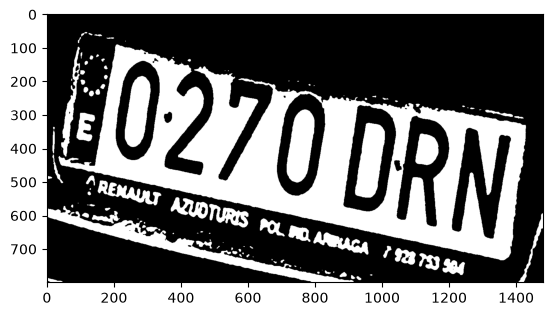

Matrícula detectada: 0270DRN


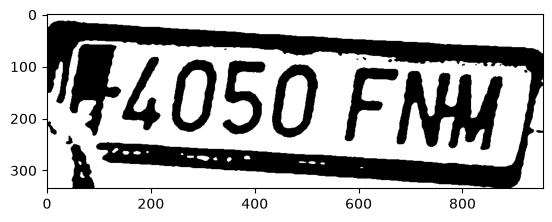

Matrícula detectada: No se detectó matrícula válida


In [ ]:
img = cv2.imread("../../image-dataset/prac4VC_dataset/images/0270DRN.JPG")

results = plate_detector_960_batch_16_small.predict(source=img, save=True, save_txt=True, conf=0.5, device=device)
for box in results[0].boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
    pad = 5
    h, w = img.shape[:2]
    recorte = img[
        max(0, int(y1) - pad) : min(h, int(y2) + pad),
            max(0, int(x1) - pad) : min(w, int(x2) + pad),
        ].copy() 
    recorte_grande = cv2.resize(
        recorte, None, fx=5, fy=5, interpolation=cv2.INTER_CUBIC
    )
    recorte_gris = cv2.cvtColor(recorte_grande, cv2.COLOR_BGR2GRAY)  
    # leer_con_easyocr(recorte_gris)
    gris_suave = cv2.GaussianBlur(recorte_gris, (5, 5), 0)
    _, recorte_bin = cv2.threshold(gris_suave, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
    plt.imshow(cv2.cvtColor(recorte_bin, cv2.COLOR_BGR2RGB))
    plt.show()
    texto = reader_easy.readtext(
    recorte_bin, detail=0, allowlist="0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"
    )    

    matricula = "No se detectó matrícula válida"
    for t in texto:
        t_limpio = t.replace(" ", "")
        if len(t_limpio) == 7:
            matricula = t_limpio
    print("Matrícula detectada:", matricula)

## Paddle OCR 

In [ ]:
import os
import torch
from transformers import AutoModel, AutoTokenizer

In [ ]:
if not torch.cuda.is_available():
    torch.Tensor.cuda = lambda self, *a, **k: self
    torch.nn.Module.cuda = lambda self, *a, **k: self

In [ ]:
model_name = "baidu/Unlimited-OCR"
path_image = "../../image-dataset/prac4VC_dataset/images/0270DRN.JPG"
tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
model = AutoModel.from_pretrained(
    model_name,
    trust_remote_code=True,
    use_safetensors=True,
    torch_dtype=torch.bfloat16,
)
model = model.eval().cuda()

[transformers] Encountered exception while importing addict: No module named 'addict'


ImportError: This modeling file requires the following packages that were not found in your environment: addict. Run `pip install addict`

In [ ]:
model.infer(
    tokenizer,
    prompt="<image>document parsing.",
    image_file=path_image,
    output_path=path_image.replace(".jpg", "_output_Unlimited"),
    base_size=1024,
    image_size=640,
    crop_mode=True,
    max_length=32768,
    no_repeat_ngram_size=35,
    ngram_window=128,
    save_results=True,
)

NameError: name 'model' is not defined

# SmolVLM


In [ ]:
from transformers import AutoModelForImageTextToText, AutoProcessor

# CELDA DE CARGA (ejecutar solo una vez)
processor = AutoProcessor.from_pretrained(
    "HuggingFaceTB/SmolVLM-Instruct",
    size={"shortest_edge": 768, "longest_edge": 768},
)
model_vlm = AutoModelForImageTextToText.from_pretrained(
    "HuggingFaceTB/SmolVLM-Instruct",
    dtype=torch.bfloat16,
    _attn_implementation="eager",
    device_map="cuda",  # carga los pesos directamente en la GPU
)
model_vlm.eval()

Loading weights: 100%|██████████| 657/657 [00:00<00:00, 975.04it/s] 


Idefics3ForConditionalGeneration(
  (model): Idefics3Model(
    (vision_model): Idefics3VisionTransformer(
      (embeddings): Idefics3VisionEmbeddings(
        (patch_embedding): Conv2d(3, 1152, kernel_size=(14, 14), stride=(14, 14), padding=valid)
        (position_embedding): Embedding(729, 1152)
      )
      (encoder): Idefics3Encoder(
        (layers): ModuleList(
          (0-26): 27 x Idefics3EncoderLayer(
            (self_attn): Idefics3VisionAttention(
              (k_proj): Linear(in_features=1152, out_features=1152, bias=True)
              (v_proj): Linear(in_features=1152, out_features=1152, bias=True)
              (q_proj): Linear(in_features=1152, out_features=1152, bias=True)
              (out_proj): Linear(in_features=1152, out_features=1152, bias=True)
            )
            (layer_norm1): LayerNorm((1152,), eps=1e-06, elementwise_affine=True)
            (mlp): Idefics3VisionMLP(
              (activation_fn): GELUTanh()
              (fc1): Linear(in_feature

In [ ]:
print(f"VRAM usada: {torch.cuda.memory_allocated()/1024**3:.2f} GB")

VRAM usada: 4.22 GB



0: 960x736 2 license_plates, 87.2ms
Speed: 16.3ms preprocess, 87.2ms inference, 9.3ms postprocess per image at shape (1, 3, 960, 736)


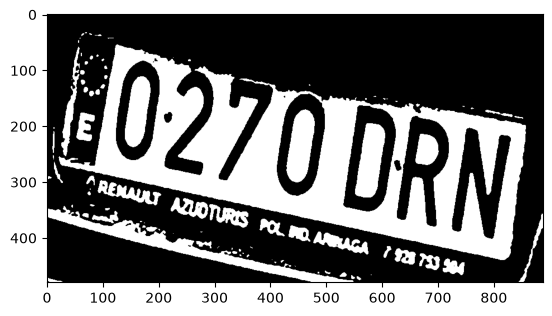

SmolVLM leyó: 0270DRN


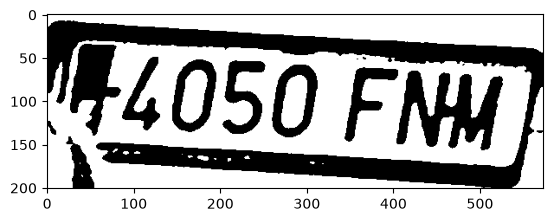

SmolVLM leyó: 4050fnm


In [ ]:
img = cv2.imread("../../image-dataset/prac4VC_dataset/images/0270DRN.JPG")

results = plate_detector_960_batch_16_small.predict(source=img, conf=0.5, device=device)

for box in results[0].boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
    pad = 5
    h, w = img.shape[:2]
    recorte = img[
        max(0, int(y1) - pad) : min(h, int(y2) + pad),
        max(0, int(x1) - pad) : min(w, int(x2) + pad),
    ].copy()

    recorte_grande = cv2.resize(
        recorte, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC
    )
    recorte_gris = cv2.cvtColor(recorte_grande, cv2.COLOR_BGR2GRAY)
    gris_suave = cv2.GaussianBlur(recorte_gris, (5, 5), 0)
    _, recorte_bin = cv2.threshold(
        gris_suave, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )  
    
    pil_img = Image.fromarray(cv2.cvtColor(recorte_bin, cv2.COLOR_BGR2RGB))

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {
                    "type": "text",
                    "text": "Read the license plate text in this image. Reply ONLY with the alphanumeric characters of the plate, without spaces or hyphens.",
                },
            ],
        },
    ]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[pil_img], return_tensors="pt").to(device)

    with torch.no_grad():
        generated_ids = model_vlm.generate(**inputs, max_new_tokens=10)
        generated_text = processor.batch_decode(
            generated_ids[:, inputs["input_ids"].shape[1] :],
            skip_special_tokens=True,
        )[0]

    plt.imshow(cv2.cvtColor(recorte_bin, cv2.COLOR_BGR2RGB))
    plt.show()
    print("SmolVLM leyó:", generated_text.strip())

In [ ]:
import time
import re
from difflib import SequenceMatcher
import pandas as pd


def limpiar_matricula(texto):
    return re.sub(r"[^A-Z0-9]", "", str(texto).upper())


# 2. Cargar imágenes del dataset junto con sus matrículas reales de los JSON
dataset_dir = Path("../../image-dataset/prac4VC_dataset")
images_dir = dataset_dir / "images"
annotations_dir = dataset_dir / "annotations"

muestras_dataset = []
for img_path in sorted(images_dir.iterdir()):
    if img_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
        continue
    json_path = annotations_dir / f"{img_path.stem}.json"
    if not json_path.exists():
        continue

    with open(json_path, "r", encoding="utf-8") as f:
        anotaciones = json.load(f)

    # Extraer matrículas reales válidas (ignorando vacías o placeholders '0000AAA')
    placas_reales = [
        limpiar_matricula(a.get("plate", ""))
        for a in anotaciones
        if limpiar_matricula(a.get("plate", "")) not in ["", "0000AAA"]
    ]

    if len(placas_reales) > 0:
        muestras_dataset.append((img_path, placas_reales))

# Seleccionar un subconjunto fijo de imágenes para evaluar en las mismas condiciones
rdm = get_random(SEED)
MAX_IMAGENES = 50  # Puedes cambiarlo (ej. 30, 50, 100)
muestras_eval = rdm.sample(
    muestras_dataset, min(MAX_IMAGENES, len(muestras_dataset))
)

print(
    f"Total imágenes válidas: {len(muestras_dataset)} | Seleccionadas para evaluar: {len(muestras_eval)}"
)

Total imágenes válidas: 2406 | Seleccionadas para evaluar: 50


In [ ]:
def preprocesar_recorte(img, box, pad=5):
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
    h, w = img.shape[:2]
    recorte = img[
        max(0, int(y1) - pad) : min(h, int(y2) + pad),
        max(0, int(x1) - pad) : min(w, int(x2) + pad),
    ].copy()
    recorte_grande = cv2.resize(
        recorte, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC
    )
    recorte_gris = cv2.cvtColor(recorte_grande, cv2.COLOR_BGR2GRAY)
    gris_suave = cv2.GaussianBlur(recorte_gris, (5, 5), 0)

    return gris_suave


# def leer_con_easyocr(recorte_gris):
#     t0 = time.perf_counter()
#     textos = reader_easy.readtext(
#         recorte_gris, detail=0, allowlist="0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"
#     )
#     t_inferencia = time.perf_counter() - t0

#     candidato = limpiar_matricula("".join(textos))
#     for t in textos:
#         t_limpio = limpiar_matricula(t)
#         if len(t_limpio) == 7:
#             candidato = t_limpio
#             break
#     return candidato, t_inferencia


def leer_con_smolvlm(recorte_gris):
    t0 = time.perf_counter()
    pil_img = Image.fromarray(cv2.cvtColor(recorte_gris, cv2.COLOR_BGR2RGB))
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {
                    "type": "text",
                    "text": "Read the license plate text in this image. Reply ONLY with the alphanumeric characters of the plate, without spaces or hyphens.",
                },
            ],
        }
    ]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[pil_img], return_tensors="pt").to(device)

    with torch.no_grad():
        generated_ids = model_vlm.generate(**inputs, max_new_tokens=10)
        generated_text = processor.batch_decode(
            generated_ids[:, inputs["input_ids"].shape[1] :],
            skip_special_tokens=True,
        )[0]

    t_inferencia = time.perf_counter() - t0
    return limpiar_matricula(generated_text), t_inferencia


def calcular_metricas_ocr(prediccion, placas_reales):
    if not prediccion:
        return 0, 0.0, ""
    mejor_real = max(
        placas_reales, key=lambda r: SequenceMatcher(None, prediccion, r).ratio()
    )
    similitud = SequenceMatcher(None, prediccion, mejor_real).ratio()
    acierto_exacto = int(prediccion == mejor_real)
    return acierto_exacto, similitud, mejor_real

In [ ]:
resultados_comparativa = []

for idx, (img_path, placas_reales) in enumerate(muestras_eval, 1):
    img = cv2.imread(str(img_path))
    if img is None:
        continue

    # 1. Detectar matrícula con plate_detector_960_batch_16_small
    t0_yolo = time.perf_counter()
    preds_yolo = plate_detector_960_batch_16_small.predict(
        source=img, conf=0.5, verbose=False, device=device
    )
    t_yolo = time.perf_counter() - t0_yolo

    cajas = preds_yolo[0].boxes

    if len(cajas) == 0:
        for nombre_ocr in ["EasyOCR", "SmolVLM"]:
            resultados_comparativa.append(
                {
                    "imagen": img_path.name,
                    "modelo_ocr": nombre_ocr,
                    "matricula_real": placas_reales[0],
                    "prediccion": "",
                    "acierto_exacto": 0,
                    "similitud_caracteres": 0.0,
                    "tiempo_ocr_s": 0.0,
                    "tiempo_total_s": t_yolo,
                }
            )
        continue

    # 2. Evaluar EasyOCR y SmolVLM sobre cada recorte detectado
    for box in cajas:
        recorte_gris = preprocesar_recorte(img, box)

        # --- EasyOCR ---
        # pred_easy, t_easy = leer_con_easyocr(recorte_gris)
        # exacto_easy, sim_easy, real_easy = calcular_metricas_ocr(
        #     pred_easy, placas_reales
        # )
        # resultados_comparativa.append(
        #     {
        #         "imagen": img_path.name,
        #         "modelo_ocr": "EasyOCR",
        #         "matricula_real": real_easy or placas_reales[0],
        #         "prediccion": pred_easy,
        #         "acierto_exacto": exacto_easy,
        #         "similitud_caracteres": sim_easy,
        #         "tiempo_ocr_s": t_easy,
        #         "tiempo_total_s": t_yolo + t_easy,
        #     }
        # )

        # --- SmolVLM ---
        pred_vlm, t_vlm = leer_con_smolvlm(recorte_gris)
        exacto_vlm, sim_vlm, real_vlm = calcular_metricas_ocr(pred_vlm, placas_reales)
        resultados_comparativa.append(
            {
                "imagen": img_path.name,
                "modelo_ocr": "SmolVLM",
                "matricula_real": real_vlm or placas_reales[0],
                "prediccion": pred_vlm,
                "acierto_exacto": exacto_vlm,
                "similitud_caracteres": sim_vlm,
                "tiempo_ocr_s": t_vlm,
                "tiempo_total_s": t_yolo + t_vlm,
            }
        )

    if idx % 10 == 0 or idx == len(muestras_eval):
        print(f"Procesadas {idx}/{len(muestras_eval)} imágenes...")

# Convertir a DataFrame y mostrar tabla resumen comparando EasyOCR vs SmolVLM
df_resultados = pd.DataFrame(resultados_comparativa)

resumen = (
    df_resultados.groupby("modelo_ocr")
    .agg(
        matriculas_evaluadas=("imagen", "count"),
        tasa_acierto_exacto_pct=("acierto_exacto", lambda x: round(x.mean() * 100, 2)),
        similitud_media_pct=(
            "similitud_caracteres",
            lambda x: round(x.mean() * 100, 2),
        ),
        tiempo_medio_ocr_ms=("tiempo_ocr_s", lambda x: round(x.mean() * 1000, 2)),
        tiempo_medio_total_ms=("tiempo_total_s", lambda x: round(x.mean() * 1000, 2)),
    )
    .reset_index()
)

display(resumen)

Procesadas 10/50 imágenes...
Procesadas 20/50 imágenes...
Procesadas 30/50 imágenes...
Procesadas 50/50 imágenes...


,modelo_ocr,matriculas_evaluadas,tasa_acierto_exacto_pct,similitud_media_pct,tiempo_medio_ocr_ms,tiempo_medio_total_ms
0,EasyOCR,3,0.00,0.00,0.0,12.62
1,SmolVLM,81,70.37,82.52,481.6,510.48


## Testing with video FELIX